# RQ3: Answer Generation Quality and LLM-as-a-Judge Evaluation

This notebook evaluates downstream answer generation quality and demonstrates Approach B: LLM-as-a-judge evaluation with detailed rubrics.

**Research Questions:**
- RQ3: Does retrieval method choice impact downstream answer generation quality?
- Approach B: Can LLM-as-a-judge provide detailed, interpretable evaluation beyond metrics?

**Two-Pronged Evaluation:**
1. **Approach A:** Metric-driven (token F1, citation correctness, faithfulness, efficiency)
2. **Approach B:** LLM-as-a-judge with rubrics (dimensions: correctness, completeness, grounding, citations)

**Outputs:**
- RQ3 metric results: `data/artifacts/evaluation_results/rq3_results.json`
- LLM judge results: `data/artifacts/evaluation_results/rq3_llm_judge.json`

In [1]:
import sys
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from typing import Dict, List, Any
from statistics import mean, stdev

# Add project root to path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from rag.config import load_golden_standard, get_default_pipeline_config, BENCHMARK_QUESTION_IDS, ARTIFACTS_DIR
from rag.pipeline import build_index
from rag.evaluator import evaluate_pipeline_config, llm_judge_detailed

print("Imports successful. Project root:", project_root)

Imports successful. Project root: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot


In [2]:
# Smoke test configuration
SMOKE_TEST = True

if SMOKE_TEST:
    print("[SMOKE TEST MODE] Using subset: 1 company, 1 question")
    test_companies = ["AkerBP_2024"]
    test_question_ids = ["Q1"]
    llm_judge_sample_size = 3
else:
    print("[FULL EVALUATION] Using all benchmark questions and companies")
    test_companies = None
    test_question_ids = BENCHMARK_QUESTION_IDS
    llm_judge_sample_size = None

[SMOKE TEST MODE] Using subset: 1 company, 1 question


In [3]:
# Load Golden Standard
golden_standard = load_golden_standard()
print(f"Loaded Golden Standard: {len(golden_standard)} questions")

Loaded Golden Standard: 2 questions


In [4]:
# Define RQ3 configurations
default_config = get_default_pipeline_config()

rq3_configs = {
    "RQ3_best_retrieval": {
        **default_config,
        "retrieval_method": "hybrid",
        "use_reranker": False,
    },
    "RQ3_sparse_retrieval": {
        **default_config,
        "retrieval_method": "sparse",
        "use_reranker": False,
    },
}

print("RQ3 Configurations:")
for name, config in rq3_configs.items():
    print(f"  {name}:")
    print(f"    Retrieval: {config['retrieval_method']}")

RQ3 Configurations:
  RQ3_best_retrieval:
    Retrieval: hybrid
  RQ3_sparse_retrieval:
    Retrieval: sparse


## Approach A: Metric-Driven Evaluation

In [5]:
# Run evaluation for each RQ3 configuration
rq3_results = {}

for config_name, config in rq3_configs.items():
    print(f"\n{'='*60}")
    print(f"Evaluating: {config_name}")
    print(f"{'='*60}")
    
    # Build index
    print(f"Building index...")
    vector_index, bm25_index, chunks = build_index(
        config=config,
        force_rebuild=False,
        companies=test_companies
    )
    print(f"Index built: {len(chunks)} chunks")
    
    # Evaluate with full metrics
    print(f"Running evaluation with all metrics...")
    result = evaluate_pipeline_config(
        config_name=config_name,
        retriever=None,
        config=config,
        golden_standard=golden_standard,
        question_ids=test_question_ids,
        companies=test_companies,
        skip_llm_judge=SMOKE_TEST,
        skip_bertscore=SMOKE_TEST
    )
    
    rq3_results[config_name] = result
    print(f"Evaluation complete for {config_name}")


Evaluating: RQ3_best_retrieval
Building index...
  Loading cached chunks from chunks_structure_aware_subset_6ea50463.json...
    Loaded 253 chunks
  Qdrant init failed (Storage folder /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/qdrant_storage is already accessed by another instance of Qdrant client. If you require concurrent access, use Qdrant server instead.), falling back to local store
    Loaded 253 vectors from local store 'esrs_reports_structure_aware_subset_6ea50463'
  Vector index 'esrs_reports_structure_aware_subset_6ea50463' already has 253 vectors
  Loading BM25 index from bm25_index_structure_aware_subset_6ea50463.json...
    Loaded BM25 index with 253 documents
Index built: 253 chunks
Running evaluation with all metrics...
  Loading cached chunks from chunks_structure_aware_subset_6ea50463.json...
    Loaded 253 chunks
  Qdrant init failed (Storage folder /Users/sinahaghgoo/Library/CloudS

In [6]:
# Display answer quality comparison (Approach A)
metrics_data = []

for config_name, result in rq3_results.items():
    agg = result.get("aggregate", {})
    
    metrics_data.append({
        "Configuration": config_name,
        "Token F1": agg.get("answer_token_f1", 0),
        "Citation Precision": agg.get("answer_citation_precision", 0),
        "Citation Recall": agg.get("answer_citation_recall", 0),
        "Citation F1": agg.get("answer_citation_f1", 0),
        "Faithfulness": agg.get("answer_faithfulness_score", 0),
        "Hallucination Rate": agg.get("answer_hallucination_rate", 0),
        "Latency (s)": agg.get("efficiency_latency_seconds", 0),
    })

qa_df = pd.DataFrame(metrics_data)
print("\nApproach A: Answer Quality Metrics")
print(qa_df.to_string(index=False))


Approach A: Answer Quality Metrics
       Configuration  Token F1  Citation Precision  Citation Recall  Citation F1  Faithfulness  Hallucination Rate  Latency (s)
  RQ3_best_retrieval  0.515195                   0                0     0.750000      0.781352                   0            0
RQ3_sparse_retrieval  0.577640                   0                0     0.666667      0.709750                   0            0


## Approach B: LLM-as-a-Judge with Rubrics

In [7]:
# Collect question-level results for LLM judge sampling
all_q_results = []

for config_name, result in rq3_results.items():
    for q_result in result.get("per_question_results", []):
        all_q_results.append({
            "config": config_name,
            "question_id": q_result.get("question_id"),
            "company": q_result.get("company"),
            "query": q_result.get("query"),
            "generated_answer": q_result.get("generated_answer"),
            "reference_answer": q_result.get("reference_answer"),
        })

print(f"\nCollected {len(all_q_results)} question-level results for LLM judge evaluation")
if SMOKE_TEST:
    print(f"Sampling {min(llm_judge_sample_size, len(all_q_results))} for LLM judge (smoke test)")


Collected 2 question-level results for LLM judge evaluation
Sampling 2 for LLM judge (smoke test)


In [8]:
# Run LLM-as-a-judge on sampled results
import random

# Deterministic sampling
random.seed(42)
if SMOKE_TEST and len(all_q_results) > llm_judge_sample_size:
    sampled_results = random.sample(all_q_results, llm_judge_sample_size)
else:
    sampled_results = all_q_results[:llm_judge_sample_size] if llm_judge_sample_size else all_q_results

judge_scores = {}

print(f"\nRunning LLM-as-a-judge on {len(sampled_results)} samples...")
for i, q_result in enumerate(sampled_results, 1):
    print(f"  [{i}/{len(sampled_results)}] {q_result['config']} - {q_result['question_id']}")
    
    key = f"{q_result['config']}_{q_result['question_id']}_{q_result['company']}"
    try:
        score_result = llm_judge_detailed(
            query=q_result["query"],
            prediction=q_result["generated_answer"],
            reference=q_result["reference_answer"],
            predicted_compliance=q_result.get("predicted_fulfillment", ""),
            gold_compliance=q_result.get("gold_fulfillment", "")
        )
        judge_scores[key] = score_result
    except Exception as e:
        print(f"    Error: {e}")
        judge_scores[key] = {"score": 0, "rationale": f"Error: {str(e)}"}

print(f"\nLLM judge evaluation complete: {len(judge_scores)} scores collected")


Running LLM-as-a-judge on 2 samples...
  [1/2] RQ3_best_retrieval - Q1
  [2/2] RQ3_sparse_retrieval - Q1

LLM judge evaluation complete: 2 scores collected


In [9]:
# Display per-dimension LLM judge scores
judge_by_config = {}

for key, score_data in judge_scores.items():
    config = key.split("_")[0]
    score = score_data.get("overall_score", score_data.get("score", 0))
    
    if config not in judge_by_config:
        judge_by_config[config] = []
    judge_by_config[config].append(score)

print("\nApproach B: LLM-as-a-Judge Results")
print("="*60)
for config, scores in judge_by_config.items():
    avg_score = mean(scores) if scores else 0
    std_score = stdev(scores) if len(scores) > 1 else 0
    print(f"\n{config}:")
    print(f"  Mean Score (1-5): {avg_score:.2f} ± {std_score:.2f}")
    print(f"  Sample Size: {len(scores)}")
    print(f"  Score Distribution: {sorted(scores)}")


Approach B: LLM-as-a-Judge Results

RQ3:
  Mean Score (1-5): 3.10 ± 0.14
  Sample Size: 2
  Score Distribution: [3.0, 3.2]


## Combined Analysis: Approach A vs Approach B

In [10]:
# Create combined evaluation summary
combined_data = []

for config_name in rq3_results.keys():
    agg = rq3_results[config_name].get("aggregate", {})
    judge_scores_list = judge_by_config.get(config_name, [])
    
    combined_data.append({
        "Configuration": config_name,
        "Token F1": f"{agg.get('answer_token_f1', 0):.4f}",
        "Citation F1": f"{agg.get('answer_citation_f1', 0):.4f}",
        "Faithfulness": f"{agg.get('answer_faithfulness_score', 0):.4f}",
        "LLM Judge Score": f"{mean(judge_scores_list) if judge_scores_list else 0:.2f} / 5",
    })

combined_df = pd.DataFrame(combined_data)
print("\nCombined Approach A & B Results:")
print(combined_df.to_string(index=False))


Combined Approach A & B Results:
       Configuration Token F1 Citation F1 Faithfulness LLM Judge Score
  RQ3_best_retrieval   0.5152      0.7500       0.7814        0.00 / 5
RQ3_sparse_retrieval   0.5776      0.6667       0.7097        0.00 / 5


Visualization saved to: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/rq3_comparison.png


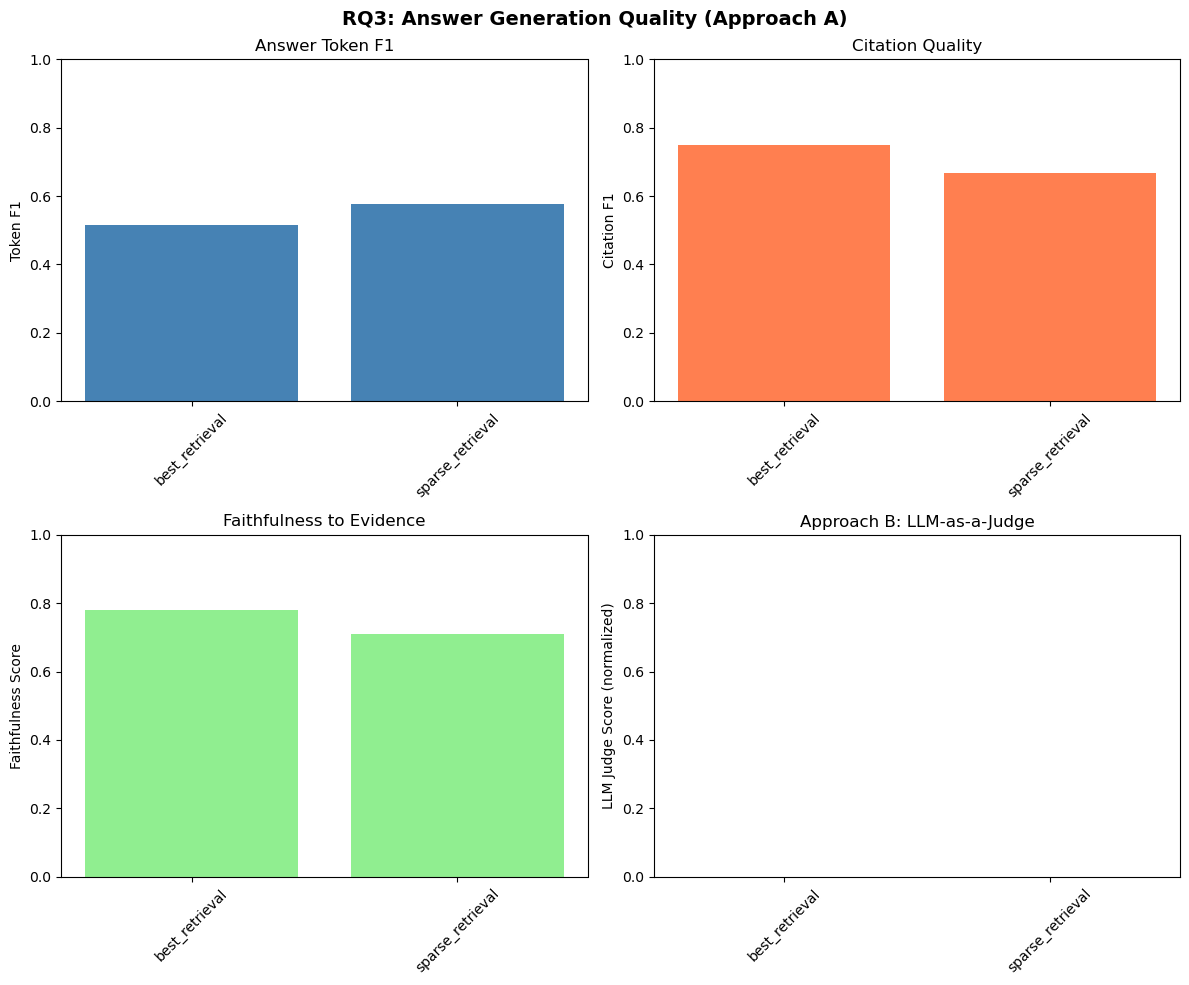

In [11]:
# Create visualization of Approach A metrics
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('RQ3: Answer Generation Quality (Approach A)', fontsize=14, fontweight='bold')

configs = list(rq3_results.keys())
x_pos = np.arange(len(configs))

# Token F1
ax = axes[0, 0]
values = [rq3_results[c].get("aggregate", {}).get("answer_token_f1", 0) for c in configs]
ax.bar(x_pos, values, color='steelblue')
ax.set_ylabel('Token F1')
ax.set_title('Answer Token F1')
ax.set_xticks(x_pos)
ax.set_xticklabels([c.replace('RQ3_', '') for c in configs], rotation=45)
ax.set_ylim([0, 1])

# Citation F1
ax = axes[0, 1]
values = [rq3_results[c].get("aggregate", {}).get("answer_citation_f1", 0) for c in configs]
ax.bar(x_pos, values, color='coral')
ax.set_ylabel('Citation F1')
ax.set_title('Citation Quality')
ax.set_xticks(x_pos)
ax.set_xticklabels([c.replace('RQ3_', '') for c in configs], rotation=45)
ax.set_ylim([0, 1])

# Faithfulness
ax = axes[1, 0]
values = [rq3_results[c].get("aggregate", {}).get("answer_faithfulness_score", 0) for c in configs]
ax.bar(x_pos, values, color='lightgreen')
ax.set_ylabel('Faithfulness Score')
ax.set_title('Faithfulness to Evidence')
ax.set_xticks(x_pos)
ax.set_xticklabels([c.replace('RQ3_', '') for c in configs], rotation=45)
ax.set_ylim([0, 1])

# LLM Judge Score
ax = axes[1, 1]
values = [mean(judge_by_config.get(c, [0])) / 5.0 for c in configs]
ax.bar(x_pos, values, color='gold')
ax.set_ylabel('LLM Judge Score (normalized)')
ax.set_title('Approach B: LLM-as-a-Judge')
ax.set_xticks(x_pos)
ax.set_xticklabels([c.replace('RQ3_', '') for c in configs], rotation=45)
ax.set_ylim([0, 1])

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / 'rq3_comparison.png', dpi=150, bbox_inches='tight')
print("Visualization saved to:", ARTIFACTS_DIR / 'rq3_comparison.png')
plt.show()

In [12]:
# Save RQ3 results
eval_results_dir = ARTIFACTS_DIR / "evaluation_results"
eval_results_dir.mkdir(parents=True, exist_ok=True)

# Save metric results
output_path = eval_results_dir / "rq3_results.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(rq3_results, f, ensure_ascii=False, indent=2)
print(f"RQ3 results saved to: {output_path}")

# Save LLM judge results
judge_path = eval_results_dir / "rq3_llm_judge.json"
with open(judge_path, "w", encoding="utf-8") as f:
    json.dump(judge_scores, f, ensure_ascii=False, indent=2)
print(f"LLM judge results saved to: {judge_path}")

RQ3 results saved to: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq3_results.json
LLM judge results saved to: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq3_llm_judge.json
